In [14]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from hyperopt import fmin, tpe, hp, Trials, STATUS_OK, space_eval
import shap

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_float32_matmul_precision("high")

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda:0
CUDA available: True
CUDA device count: 1
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


/home/aashr/-/Py/.venv/lib/python3.12/site-packages/torch/__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [4]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [5]:
df = data.drop(columns=["ID", "Type of MB", "Types of contaminants"]) 
df

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [6]:
Y = df["removal rate (%)"].astype(float)
X = df.drop(columns=["removal rate (%)"]).copy()

# Convert all features to numeric and keep only valid rows
X = X.apply(pd.to_numeric, errors="coerce")
Y = Y.loc[X.index]

print(X.head())
print("Shape:", X.shape)

    pH  Compound Mw (g/mol)  Compound charge  Compound Kow  \
0  7.0              162.229              0.0         0.711   
1  7.0              113.160              0.0         0.310   
2  7.0              131.135              0.0        -2.864   
3  7.0               30.026              0.0        -0.467   
4  7.0               60.096              0.0         0.255   

   min projection (Å)  max projection (Å)  MB MWCO (Da)  MB contact angle (°)  \
0                3.25                8.08           150                  50.0   
1                3.92                4.01           150                  50.0   
2                3.35                4.36           150                  50.0   
3                2.08                2.34           150                  50.0   
4                2.95                3.36           150                  50.0   

   MB zeta potential  Total charge  Pressure (kPa)  Measurement time (min)  \
0               -1.0           0.0           800.0            

In [7]:
X["Compound Kow"] = pd.to_numeric(X["Compound Kow"], errors="coerce")
# X = X.dropna()
Y = Y.loc[X.index]

print("Negative Kow count:", int((X["Compound Kow"] < 0).sum()))
print("Final X shape:", X.shape)

Negative Kow count: 319
Final X shape: (1906, 14)


In [8]:
X = X.replace([np.inf, -np.inf], np.nan)

valid_idx = X.dropna().index
X = X.loc[valid_idx]
Y = Y.loc[valid_idx]

print("Final shape after removing invalid rows:", X.shape)

Final shape after removing invalid rows: (1906, 14)


In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [10]:
X_np = X.to_numpy(dtype=np.float32)
Y_np = Y.to_numpy(dtype=np.float32).reshape(-1, 1)

all_indices = np.arange(len(X_np))
train_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=seed
)

X_train_raw = X_np[train_idx]
X_test_raw = X_np[test_idx]
y_train_raw = Y_np[train_idx]
y_test_raw = Y_np[test_idx]

feature_names = X.columns.tolist()

print("Train shape:", X_train_raw.shape)
print("Test shape:", X_test_raw.shape)

np.save("train_indices.npy", train_idx)
np.save("test_indices.npy", test_idx)

Train shape: (1524, 14)
Test shape: (382, 14)


In [11]:
class ANNModel(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout, activation):
        super().__init__()

        activation_layers = {
            "relu": nn.ReLU,
            "leaky_relu": lambda: nn.LeakyReLU(negative_slope=0.01),
            "gelu": nn.GELU
        }
        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_layers[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim

        layers.append(nn.Linear(current_dim, 1))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [ ]:
param_space_ann = {
    "architecture": hp.choice(
        "ann_architecture",
        [[64, 32], [128, 64, 32], [128, 64, 32, 32], [256, 128, 64], [256, 128, 64, 32]]
    ),
    "learning_rate": hp.loguniform("ann_learning_rate", np.log(1e-5), np.log(3e-3)),
    "batch_size": hp.choice("ann_batch_size", [16, 32, 64, 128]),
    "dropout": hp.uniform("ann_dropout", 0.0, 0.30),
    "weight_decay": hp.loguniform("ann_weight_decay", np.log(1e-6), np.log(1e-2)),
    "activation": hp.choice("ann_activation", ["relu", "leaky_relu", "gelu"]),
    "optimizer": hp.choice("ann_optimizer", ["adam", "adamw"])
}

print("Hyperparameter search space ready.")

Hyperparameter search space ready.


In [ ]:
def set_seed(value=seed):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(value)
        torch.cuda.manual_seed_all(value)


def objective_ann(params):
    kf = KFold(n_splits=5, shuffle=True, random_state=seed)
    fold_r2_scores = []
    fold_best_epochs = []

    for fold, (fold_train_idx, fold_val_idx) in enumerate(kf.split(X_train_raw)):
        fold_seed = seed + fold
        set_seed(fold_seed)

        scaler_fold = StandardScaler()
        X_fold_train = np.ascontiguousarray(scaler_fold.fit_transform(X_train_raw[fold_train_idx]), dtype=np.float32)
        X_fold_val = np.ascontiguousarray(scaler_fold.transform(X_train_raw[fold_val_idx]), dtype=np.float32)
        y_fold_train = np.ascontiguousarray(y_train_raw[fold_train_idx], dtype=np.float32)
        y_fold_val = np.ascontiguousarray(y_train_raw[fold_val_idx], dtype=np.float32)

        X_fold_train_cpu = torch.from_numpy(X_fold_train)
        y_fold_train_cpu = torch.from_numpy(y_fold_train)
        X_fold_val_gpu = torch.from_numpy(X_fold_val).to(device, non_blocking=True)
        y_fold_val_gpu = torch.from_numpy(y_fold_val).to(device, non_blocking=True)

        loader = DataLoader(
            TensorDataset(X_fold_train_cpu, y_fold_train_cpu),
            batch_size=params["batch_size"],
            shuffle=True,
            pin_memory=torch.cuda.is_available(),
            num_workers=0,
            generator=torch.Generator().manual_seed(fold_seed)
        )

        model = ANNModel(
            input_dim=X_fold_train.shape[1],
            hidden_layers=params["architecture"],
            dropout=params["dropout"],
            activation=params["activation"]
        ).to(device)

        optimizer_class = optim.Adam if params["optimizer"] == "adam" else optim.AdamW
        optimizer = optimizer_class(
            model.parameters(),
            lr=params["learning_rate"],
            weight_decay=params["weight_decay"]
        )
        criterion = nn.MSELoss()
        best_val_loss = float("inf")
        best_state = None
        best_epoch = 0
        patience_counter = 0

        for epoch in range(2500):
            model.train()
            for xb_cpu, yb_cpu in loader:
                xb = xb_cpu.to(device, non_blocking=True)
                yb = yb_cpu.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(xb), yb)
                loss.backward()
                optimizer.step()

            model.eval()
            with torch.no_grad():
                val_loss = criterion(model(X_fold_val_gpu), y_fold_val_gpu).item()

            if val_loss < best_val_loss - 1e-5:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch + 1
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= 100:
                break

        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            fold_predictions = model(X_fold_val_gpu).cpu().numpy().ravel()

        fold_r2_scores.append(r2_score(y_fold_val.ravel(), fold_predictions))
        fold_best_epochs.append(best_epoch)

        del model, loader, X_fold_val_gpu, y_fold_val_gpu
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    mean_r2 = float(np.mean(fold_r2_scores))
    return {
        "loss": -mean_r2,
        "status": STATUS_OK,
        "mean_r2": mean_r2,
        "best_epochs": fold_best_epochs,
        "mean_best_epoch": int(np.round(np.mean(fold_best_epochs)))
    }


print("Starting ANN Hyperopt optimization...")
trials_ann = Trials()
best_ann_raw = fmin(
    fn=objective_ann,
    space=param_space_ann,
    algo=tpe.suggest,
    max_evals=50,
    trials=trials_ann,
    rstate=np.random.default_rng(seed)
)

best_ann_params = space_eval(param_space_ann, best_ann_raw)
best_trial_result = trials_ann.best_trial["result"]
best_cv_r2 = best_trial_result["mean_r2"]
final_epochs = best_trial_result["mean_best_epoch"]

print("\nBest Hyperparameters:")
for key, value in best_ann_params.items():
    print(f"{key}: {value}")
print(f"Best 5-fold CV R²: {best_cv_r2:.4f}")
print(f"Selected final epochs: {final_epochs}")

In [ ]:
final_scaler = StandardScaler()
X_train_scaled = np.ascontiguousarray(final_scaler.fit_transform(X_train_raw), dtype=np.float32)
X_test_scaled = np.ascontiguousarray(final_scaler.transform(X_test_raw), dtype=np.float32)
y_train_cpu = torch.from_numpy(np.ascontiguousarray(y_train_raw, dtype=np.float32))

X_train_cpu = torch.from_numpy(X_train_scaled)
X_test = torch.from_numpy(X_test_scaled).to(device, non_blocking=True)
y_test = torch.from_numpy(np.ascontiguousarray(y_test_raw, dtype=np.float32)).to(device, non_blocking=True)

set_seed(seed)
final_loader = DataLoader(
    TensorDataset(X_train_cpu, y_train_cpu),
    batch_size=best_ann_params["batch_size"],
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
    num_workers=0,
    generator=torch.Generator().manual_seed(seed)
)

model = ANNModel(
    input_dim=X_train_scaled.shape[1],
    hidden_layers=best_ann_params["architecture"],
    dropout=best_ann_params["dropout"],
    activation=best_ann_params["activation"]
).to(device)

optimizer_class = optim.Adam if best_ann_params["optimizer"] == "adam" else optim.AdamW
optimizer = optimizer_class(
    model.parameters(),
    lr=best_ann_params["learning_rate"],
    weight_decay=best_ann_params["weight_decay"]
)
criterion = nn.MSELoss()

print("Model device:", next(model.parameters()).device)
print("Pinned-memory loader:", final_loader.pin_memory)
print(f"Training final ANN for {final_epochs} epochs...")
for epoch in range(final_epochs):
    model.train()
    epoch_loss = 0.0
    for xb_cpu, yb_cpu in final_loader:
        xb = xb_cpu.to(device, non_blocking=True)
        yb = yb_cpu.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    if (epoch + 1) % 100 == 0 or epoch == 0 or epoch + 1 == final_epochs:
        print(f"Epoch [{epoch + 1}/{final_epochs}] Loss: {epoch_loss:.6f}")

model.eval()
with torch.no_grad():
    y_pred = model(X_test).cpu().numpy().ravel()
    y_true = y_test.cpu().numpy().ravel()

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print("\nANN FINAL TEST METRICS")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

MSE: 328.3549
RMSE: 18.1206
MAE: 11.7604
R² Score: 0.5700


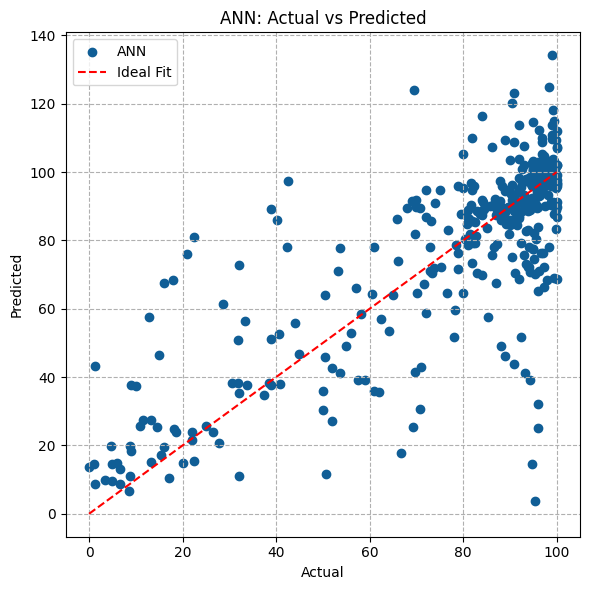

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, color="#105e96", label='ANN')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', label='Ideal Fit')
plt.xlabel("Actual")
plt.ylabel("Predicted") 
plt.title("ANN: Actual vs Predicted")
plt.legend()
plt.grid(True, linestyle='--')
plt.tight_layout()
plt.show()


,feature,mean_abs_shap
6,MB MWCO (Da),9.671699
13,compound size (nm),9.509628
9,Total charge,8.531292
7,MB contact angle (°),8.287032
1,Compound Mw (g/mol),8.120784
2,Compound charge,7.464107
3,Compound Kow,6.185529
10,Pressure (kPa),5.865178
5,max projection (Å),5.155504
0,pH,4.545284


/tmp/ipykernel_5487/464748988.py:31: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


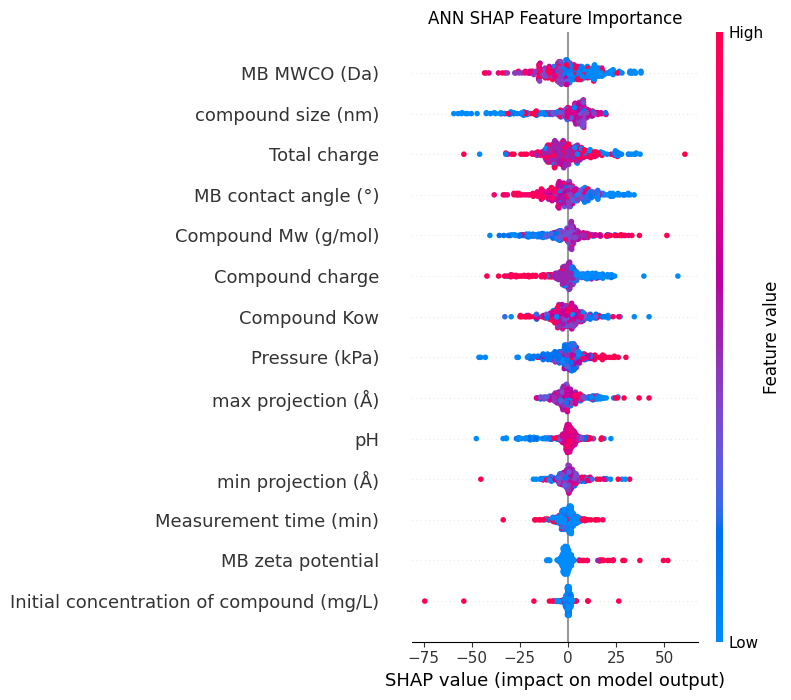

/tmp/ipykernel_5487/464748988.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


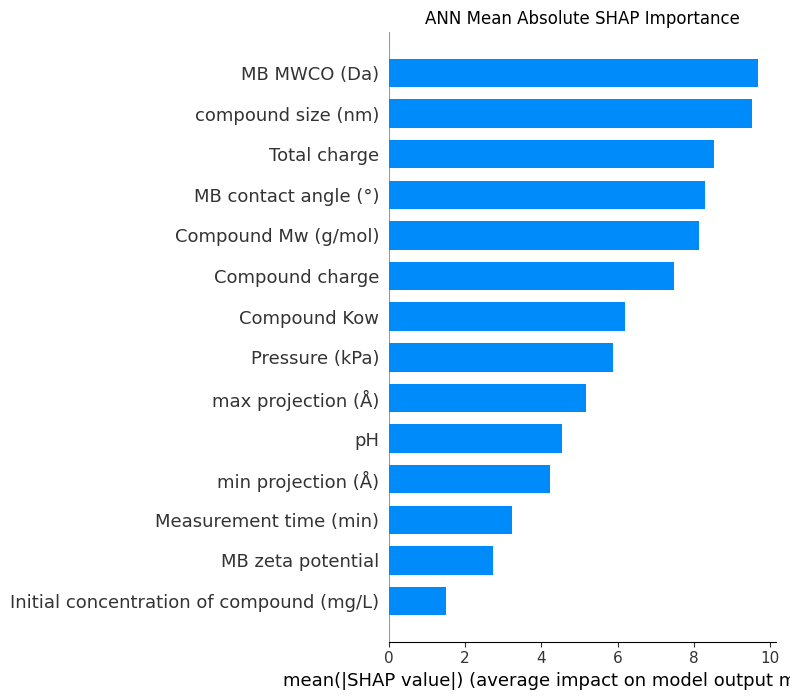

In [ ]:
model.eval()

# Move the SHAP background to the same device as the trained ANN.
background = X_train_cpu.to(device, non_blocking=True)
explain_data = X_test

explainer = shap.DeepExplainer(model, background)
raw_shap_values = explainer.shap_values(explain_data)

if isinstance(raw_shap_values, list):
    shap_values = raw_shap_values[0]
else:
    shap_values = raw_shap_values

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 0]

features = explain_data.cpu().numpy()

importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(importance)

shap.summary_plot(
    shap_values,
    features=features,
    feature_names=X.columns,
    show=False
)
plt.title("ANN SHAP Feature Importance")
plt.tight_layout()
plt.show()

shap.summary_plot(
    shap_values,
    features=features,
    feature_names=X.columns,
    plot_type="bar",
    show=False
)
plt.title("ANN Mean Absolute SHAP Importance")
plt.tight_layout()
plt.show()